# 10 · Ocean temperature and atmospheric circulation

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/10-ocean-and-circulation.ipynb)



Browser-only piplite prepares numpy, pandas, matplotlib and Plotly 6.5.0; native kernels use installed scientific packages. Local calculations use bundled helpers and inputs; Plotly rendering can require its versioned CDN and WebGL. Seeded monthly examples are synthetic. The C3S warming-level table gives model windows, Natural Earth provides real generalized coastlines, and the CDS catalogue is metadata. No authenticated CDS request, archive download or native regridding is run.

**Provenance:** `content/10-ocean-and-circulation.ipynb` at `b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a`; original SHA-256 `d10334a3a3e536f94b703a583f55e362093a6103d9519fdd56bb1a8922f741e7`. Original course material MIT; C3S auxiliary table Apache-2.0, Natural Earth public domain and CDS catalogue metadata CC BY 4.0. Preserve source credits, licenses and artwork provenance.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original climate-globe illustration introducing Ocean temperature and atmospheric circulation; illustrative, not a data map](assets/atlas-splash.png)

# 10 · Ocean temperature and atmospheric circulation

**Guiding question:** What can a spatial pattern tell you that a global average cannot?

**Data:** Synthetic teaching examples  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-15  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** in-memory tables and figures; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=10-ocean-and-circulation.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Sea-surface temperature describes the ocean surface, not the whole ocean's heat
       content. Sea-level pressure patterns help describe atmospheric circulation, but
       a pressure map alone does not establish the cause of a temperature anomaly.

       Mask land before interpreting a real SST field. Seasonal cycles and reference
       periods must match before comparing anomalies. These analytic fields are fictional
       and illustrate map reading; they are not reconstructed events.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Compare two spatial fields

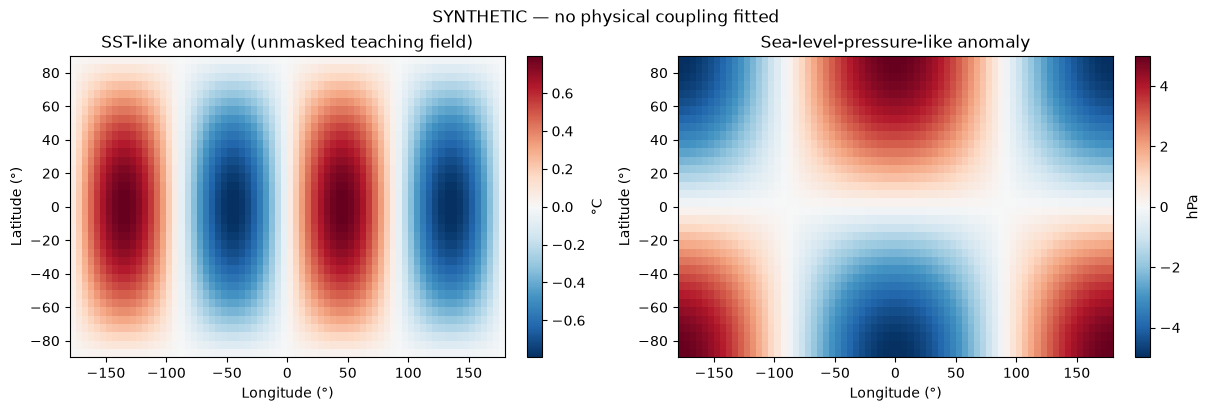

In [2]:
lon, lat, _ = regular_grid()
xx, yy = np.meshgrid(lon, lat)
sst_anomaly = 0.8*np.cos(np.deg2rad(yy))*np.sin(2*np.deg2rad(xx))
pressure_anomaly = 5*np.sin(np.deg2rad(yy))*np.cos(np.deg2rad(xx))
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, field, title, unit in zip(axes, [sst_anomaly, pressure_anomaly],
        ["SST-like anomaly (unmasked teaching field)", "Sea-level-pressure-like anomaly"], ["°C", "hPa"]):
    lim = np.abs(field).max()
    m = ax.pcolormesh(lon, lat, field, cmap="RdBu_r", vmin=-lim, vmax=lim, shading="auto")
    ax.set(xlabel="Longitude (°)", ylabel="Latitude (°)", title=title)
    fig.colorbar(m, ax=ax, label=unit)
fig.suptitle("SYNTHETIC — no physical coupling fitted")
plt.show()

## Make the comparison limits explicit

In [3]:
display(pd.DataFrame({
    "quantity": ["SST anomaly", "Pressure anomaly"],
    "unit": ["°C", "hPa"],
    "required metadata": ["ocean mask, source product, baseline", "reference level, source product, baseline"],
    "cannot infer alone": ["total ocean heat content", "a causal effect on local rainfall"],
}))

,quantity,unit,required metadata,cannot infer alone
0,SST anomaly,°C,"ocean mask, source product, baseline",total ocean heat content
1,Pressure anomaly,hPa,"reference level, source product, baseline",a causal effect on local rainfall


## Try it and explain

Why is a colour match between these two maps not a numerical match?

**Interpretation check:** The variables use different units and scales. Spatial alignment also does not establish a physical causal relationship.

## Transfer to the official Atlas

Explore SST from an ocean or satellite product and sea-level pressure from an atmospheric product. Keep their provenance separate.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/credits.md) and [data guide](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/data-guide.md).

**Continue:** [Scenarios, models, and ensemble spread](11-scenarios-and-ensembles.ipynb)